# Supplemental Figure 2, Panel I

Pairwise comparison of MDI feature importance and ridge regression coefficients between models trained using BAFdep metrics from different BAFinh doses. Plots are arrange as described for Supplemental Figure 2F

*Output: PanelI.pdf*

# Setup

In [7]:
library(tidyverse)
library(patchwork)
library(ggrepel)
library(RColorBrewer)
library(here)
here::i_am("figures/SuppFig2/PanelI/PanelI.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank()))


here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig2/PanelI

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



# Load data

In [9]:
#feature importance metrics (MDI and ridge regression coeff) from enhancer models trained using BAFdep metrics from BAFinh dose series @ 6h
dat_10nM <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "dose_10nM", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

dat_100nM <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "dose_100nM", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

dat_1uM <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "dose_1uM", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

dat_10uM <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "dose_10uM", "feature_importance.csv"
  ),
  sep = ","
) %>%
  arrange(feature)

In [3]:
# Generate plots

In [4]:
plots <- list()
all_dat <- list(dat_10nM, dat_100nM, dat_1uM, dat_10uM)
labels <- c("10nM", "100nM", "1uM", "10uM")

for (i in 1:4) {
    rowplot <- list()
  
    for (j in 1:4) {
        if (i == j) {
          plot <- ggplot() + theme_void()
      
        } else if (j < i) {
            lims <- c(-0.1,0.2)
            plot <- ggplot(data = data.frame(y = all_dat[[i]]$Ridge_coef,
                                           x = all_dat[[j]]$Ridge_coef),
                         aes(x = x, y = y)) +
            geom_point(size=.5) + geom_smooth(method=lm, se=F, color="firebrick") + xlab(labels[j]) + ylab(labels[i]) +
            coord_fixed(ratio = 1, xlim=lims, ylim=lims) + 
            scale_x_continuous(breaks=c(-0.1,0,0.1)) + scale_y_continuous(breaks=c(-0.1,0,0.1))

        } else {
            cor_val <- cor(all_dat[[j]]$Ridge_coef, all_dat[[i]]$Ridge_coef, use = "complete.obs")
            plot <- ggplot(data = data.frame(x = 1, y = 1, value = cor_val),
                         aes(x = x, y = y)) +
            geom_tile(aes(fill = value)) +
            scale_fill_gradient2(low = "white", high = "firebrick", limits = c(0, 1)) +
            geom_text(aes(label = format(value, digits=3))) + xlab(labels[j]) + ylab(labels[i]) + coord_fixed()
            }
    
    rowplot[[j]] <- plot
    }
  
    plots[[i]] <- rowplot
}

p1 <- wrap_plots(plotlist = unlist(plots, recursive = FALSE), ncol = 4) + 
    plot_layout(guides = "collect") & theme(legend.position = "right") 


In [5]:
plots <- list()
all_dat <- list(dat_10nM, dat_100nM, dat_1uM, dat_10uM)
labels <- c("10nM", "100nM", "1uM", "10uM")

for (i in 1:4) {
    rowplot <- list()
  
    for (j in 1:4) {
        if (i == j) {
          plot <- ggplot() + theme_void()
      
        } else if (j < i) {
            lims <- c(0,0.08)
            plot <- ggplot(data = data.frame(y = all_dat[[i]]$MDI_importance,
                                           x = all_dat[[j]]$MDI_importance),
                         aes(x = x, y = y)) +
            geom_point(size=.5) + geom_smooth(method=lm, se=F, color="firebrick") + xlab(labels[j]) + ylab(labels[i]) +
            coord_fixed(ratio = 1, xlim=lims, ylim=lims) +
            scale_x_continuous(breaks=c(0,0.04,0.08)) + scale_y_continuous(breaks=c(0,0.04,0.08))


        } else {
            cor_val <- cor(all_dat[[j]]$MDI_importance, all_dat[[i]]$MDI_importance, use = "complete.obs")
            plot <- ggplot(data = data.frame(x = 1, y = 1, value = cor_val),
                         aes(x = x, y = y)) +
            geom_tile(aes(fill = value)) +
            scale_fill_gradient2(low = "white", high = "firebrick", limits = c(0, 1)) +
            geom_text(aes(label = format(value, digits=3))) + xlab(labels[j]) + ylab(labels[i]) + coord_fixed()             }
    
    rowplot[[j]] <- plot
    }
  
    plots[[i]] <- rowplot
}

p2 <- wrap_plots(plotlist = unlist(plots, recursive = FALSE), ncol = 4) + 
    plot_layout(guides = "collect") & theme(legend.position = "right") 


# Assemble figure panel

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
Saving 12 x 7 in image
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


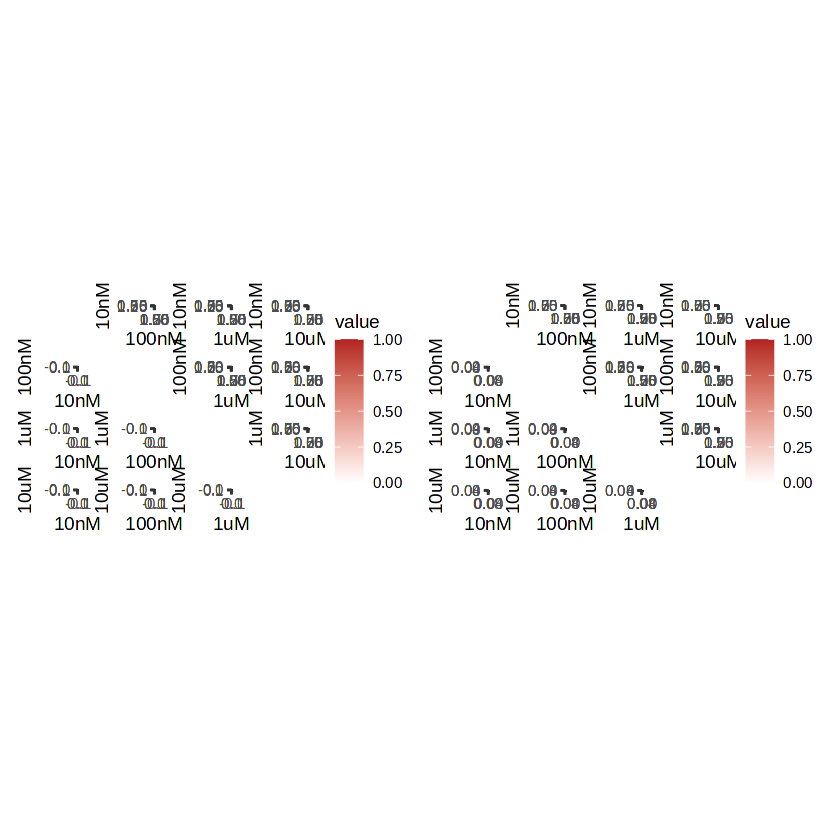

In [6]:
p1 | p2
ggsave("PanelI.pdf", width=12)